In [6]:
from google.colab import files

uploaded = files.upload()

Saving train.csv to train.csv


In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the Titanic dataset
df = pd.read_csv("train.csv")

# Display the first 10 rows
print("First 10 rows:")
display(df.head(10))

# Display dataset information
print("Dataset Information:")
df.info()

# Display statistical summary
print("\nStatistical Summary:")
display(df.describe())

# Check dataset dimensions
print("\nDataset Shape:", df.shape)

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

First 10 rows:


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
5,6,0,3,"Moran, Mr. James",male,NaN,0,0,330877,8.4583,NaN,Q
6,7,0,1,"McCarthy, Mr. Timothy J",male,54.0,0,0,17463,51.8625,E46,S
7,8,0,3,"Palsson, Master. Gosta Leonard",male,2.0,3,1,349909,21.0750,NaN,S
8,9,1,3,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",female,27.0,0,2,347742,11.1333,NaN,S
9,10,1,2,"Nasser, Mrs. Nicholas (Adele Achem)",female,14.0,1,0,237736,30.0708,NaN,C


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB

Statistical Summary:


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200



Dataset Shape: (891, 12)

Missing Values:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


In [8]:
# Create a working copy
df_clean = df.copy()

# Fill missing Age values using the median
df_clean["Age"] = df_clean["Age"].fillna(
    df_clean["Age"].median()
)

# Fill missing Embarked values using the mode
df_clean["Embarked"] = df_clean["Embarked"].fillna(
    df_clean["Embarked"].mode()[0]
)

# Drop Cabin because many of its values are missing
df_clean = df_clean.drop(columns=["Cabin"])

# Check missing values after cleaning
print("Missing values after cleaning:")
print(df_clean.isnull().sum())

Missing values after cleaning:
PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64


In [9]:
from sklearn.preprocessing import LabelEncoder, OneHotEncoder

# Create a copy for the encoding assignment
df_encoded = df_clean.copy()

# Label encode the Sex column
sex_encoder = LabelEncoder()

df_encoded["Sex"] = sex_encoder.fit_transform(
    df_encoded["Sex"]
)

# One-hot encode the Embarked column
embarked_encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

embarked_array = embarked_encoder.fit_transform(
    df_encoded[["Embarked"]]
)

# Convert encoded values into a DataFrame
embarked_df = pd.DataFrame(
    embarked_array,
    columns=embarked_encoder.get_feature_names_out(["Embarked"]),
    index=df_encoded.index
)

# Remove the original Embarked column
df_encoded = df_encoded.drop(columns=["Embarked"])

# Add the one-hot encoded columns
df_encoded = pd.concat(
    [df_encoded, embarked_df],
    axis=1
)

print("Encoded dataset:")
display(df_encoded.head())

print("\nEncoded column names:")
print(df_encoded.columns.tolist())

Encoded dataset:


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked_C,Embarked_Q,Embarked_S
0,1,0,3,"Braund, Mr. Owen Harris",1,22.0,1,0,A/5 21171,7.2500,0.0,0.0,1.0
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",0,38.0,1,0,PC 17599,71.2833,1.0,0.0,0.0
2,3,1,3,"Heikkinen, Miss. Laina",0,26.0,0,0,STON/O2. 3101282,7.9250,0.0,0.0,1.0
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",0,35.0,1,0,113803,53.1000,0.0,0.0,1.0
4,5,0,3,"Allen, Mr. William Henry",1,35.0,0,0,373450,8.0500,0.0,0.0,1.0



Encoded column names:
['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Embarked_C', 'Embarked_Q', 'Embarked_S']


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

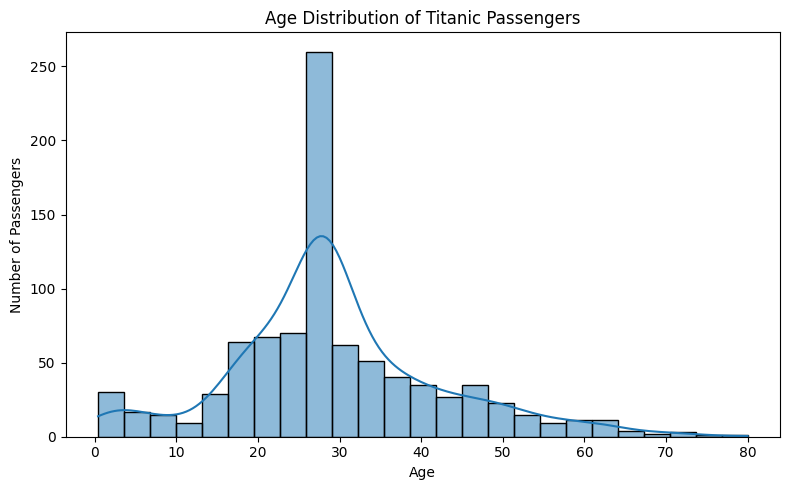

In [10]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df_clean,
    x="Age",
    bins=25,
    kde=True
)

plt.title("Age Distribution of Titanic Passengers")
plt.xlabel("Age")
plt.ylabel("Number of Passengers")

plt.tight_layout()
plt.savefig("titanic_age_distribution.png", dpi=300)
plt.show()

In [12]:
# Save the cleaned dataset
df_clean.to_csv(
    "titanic_cleaned.csv",
    index=False
)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [13]:
from google.colab import files

files.download("titanic_cleaned.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Practice Question

In [14]:
# Import pandas
import pandas as pd

# Load the Titanic dataset
df = pd.read_csv("train.csv")

# Display first 10 rows
print("First 10 rows of the dataset:")
display(df.head(10))

First 10 rows of the dataset:


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
5,6,0,3,"Moran, Mr. James",male,NaN,0,0,330877,8.4583,NaN,Q
6,7,0,1,"McCarthy, Mr. Timothy J",male,54.0,0,0,17463,51.8625,E46,S
7,8,0,3,"Palsson, Master. Gosta Leonard",male,2.0,3,1,349909,21.0750,NaN,S
8,9,1,3,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",female,27.0,0,2,347742,11.1333,NaN,S
9,10,1,2,"Nasser, Mrs. Nicholas (Adele Achem)",female,14.0,1,0,237736,30.0708,NaN,C


In [15]:
import pandas as pd

# Create a sample housing dataset
housing_data = {
    "Area": [
        500, 600, 700, 800, 900,
        1000, 1100, 1200, 1300, 1400,
        1500, 1600, 1700, 1800, 1900,
        2000, 2100, 2200, 2300, 2400
    ],

    "Price": [
        22, 25, 29, 32, 36,
        39, 43, 47, 50, 54,
        58, 61, 65, 69, 72,
        76, 80, 83, 87, 91
    ]
}

housing_df = pd.DataFrame(housing_data)

print("Housing Dataset:")
display(housing_df)
from sklearn.model_selection import train_test_split

# Features and target
X = housing_df[["Area"]]
y = housing_df["Price"]

# Split into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training data:", len(X_train))
print("Testing data:", len(X_test))

print("\nTraining features:")
display(X_train)

print("\nTesting features:")
display(X_test)

Housing Dataset:


,Area,Price
0,500,22
1,600,25
2,700,29
3,800,32
4,900,36
5,1000,39
6,1100,43
7,1200,47
8,1300,50
9,1400,54


Training data: 16
Testing data: 4

Training features:


,Area
8,1300
5,1000
11,1600
3,800
18,2300
16,2100
13,1800
2,700
9,1400
19,2400



Testing features:


,Area
0,500
17,2200
15,2000
1,600


In [16]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

# Create the Linear Regression model
model = LinearRegression()

# Train the model
model.fit(X_train, y_train)

# Predict prices using testing data
y_pred = model.predict(X_test)

# Evaluate the model
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("Linear Regression Model Results")

print("Actual Prices:")
print(y_test.values)

print("\nPredicted Prices:")
print(y_pred.round(2))

print("\nMean Absolute Error:", round(mae, 2))
print("R2 Score:", round(r2, 4))

Linear Regression Model Results
Actual Prices:
[22 83 76 25]

Predicted Prices:
[21.12 83.39 76.07 24.78]

Mean Absolute Error: 0.39
R2 Score: 0.9997


In [17]:
# Take house area as input
area = float(input("Enter house area in square feet: "))

# Create input DataFrame
new_house = pd.DataFrame({
    "Area": [area]
})

# Predict house price
predicted_price = model.predict(new_house)

print("\nHouse Area:", area, "sq ft")
print("Predicted House Price:", round(predicted_price[0], 2), "Lakhs")

Enter house area in square feet: 1500

House Area: 1500.0 sq ft
Predicted House Price: 57.75 Lakhs
